In [1]:
import os
import importlib

import read_utils
import plot_utils
import train_utils
import artificializer

importlib.reload(read_utils)
importlib.reload(plot_utils)
importlib.reload(train_utils)
importlib.reload(artificializer)

import numpy as np
import pandas as pd

In [2]:
path = f'{os.getcwd()}/../data/{os.path.basename(os.getcwd())}/exported_data_/'
filenames, continuous_behaviors, discrete_states, eigenworms, kymographs, traces = read_utils.get_data(path)

path_gfp = f'{os.getcwd()}/../data/{os.path.basename(os.getcwd())}/exported_data_gfp/'
filenames_gfp, continuous_behaviors_gfp, discrete_states_gfp, eigenworms_gfp, kymographs_gfp, traces_gfp = read_utils.get_data(path_gfp)

for i in range(len(filenames)):
	mask = eigenworms[i].notna().all(axis=1)
	#continuous_behaviors[i] = continuous_behaviors[i][mask]
	discrete_states[i] = discrete_states[i][mask]
	eigenworms[i] = eigenworms[i][mask]
	traces[i] = traces[i][mask]

	#kymographs[i] = kymographs[i][mask]
	#filenames[i] = filenames[i][mask]

for i in range(len(filenames_gfp)):
	mask = eigenworms_gfp[i].notna().all(axis=1)
	#continuous_behaviors_gfp[i] = continuous_behaviors_gfp[i][mask]
	discrete_states_gfp[i] = discrete_states_gfp[i][mask]
	eigenworms_gfp[i] = eigenworms_gfp[i][mask]
	traces_gfp[i] = traces_gfp[i][mask]

	#kymographs_gfp[i] = kymographs_gfp[i][mask]
	#filenames_gfp[i] = filenames_gfp[i][mask]

In [3]:
filenames_art = list()
discrete_states_art = discrete_states_gfp.copy()
eigenworms_art = eigenworms_gfp.copy()
traces_art = list()
traces_residual_art = list()
modes_manifold_art = list()
for i in range(len(filenames_gfp)):
	art_filename, art_trace, art_trace_residual, mode_manifold_art, art_params = artificializer.artificialize(filenames_gfp[i], traces_gfp[i].columns, eigenworms_gfp[i], discrete_states_gfp[i])
	filenames_art.append(art_filename)
	traces_art.append(art_trace)
	traces_residual_art.append(art_trace_residual)
	modes_manifold_art.append(mode_manifold_art)

# a_traces.to_csv(f'./in/{a_name}_traces.csv', index=False)
# a_traces_residual.to_csv(f'./in/{a_name}_tracesresidual.csv', index=False)

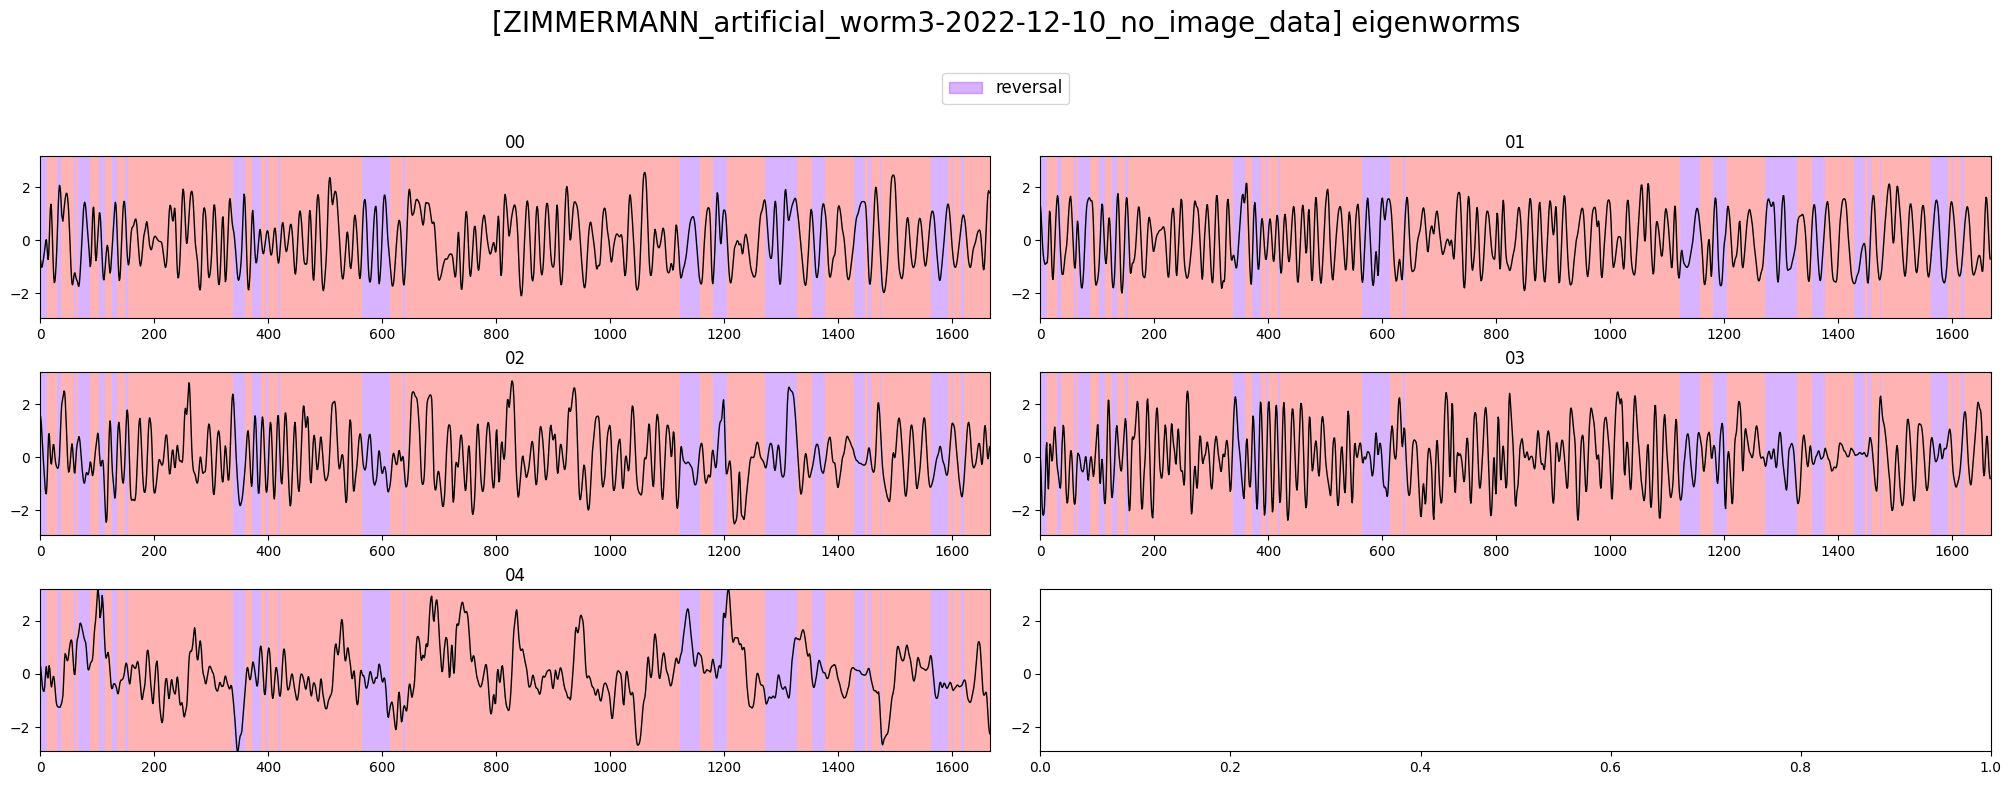

In [4]:
plot_utils.plot_traces(eigenworms[0], discrete_states_art[0]['REV'], f'[{filenames_art[0]}] eigenworms', max_plots=5)

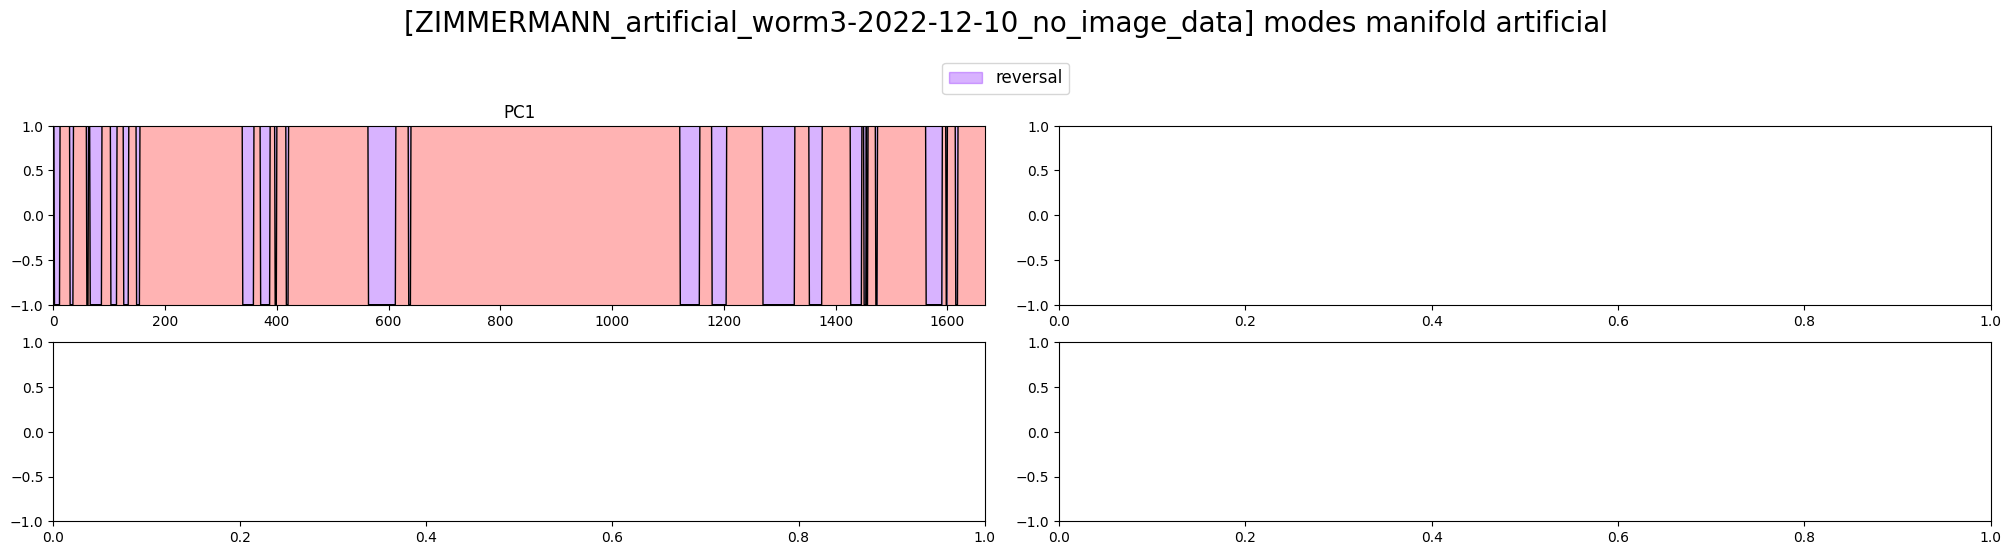

In [5]:
plot_utils.plot_traces(modes_manifold_art[0], discrete_states_art[0]['REV'], f'[{filenames_art[0]}] modes manifold artificial', max_plots=4)

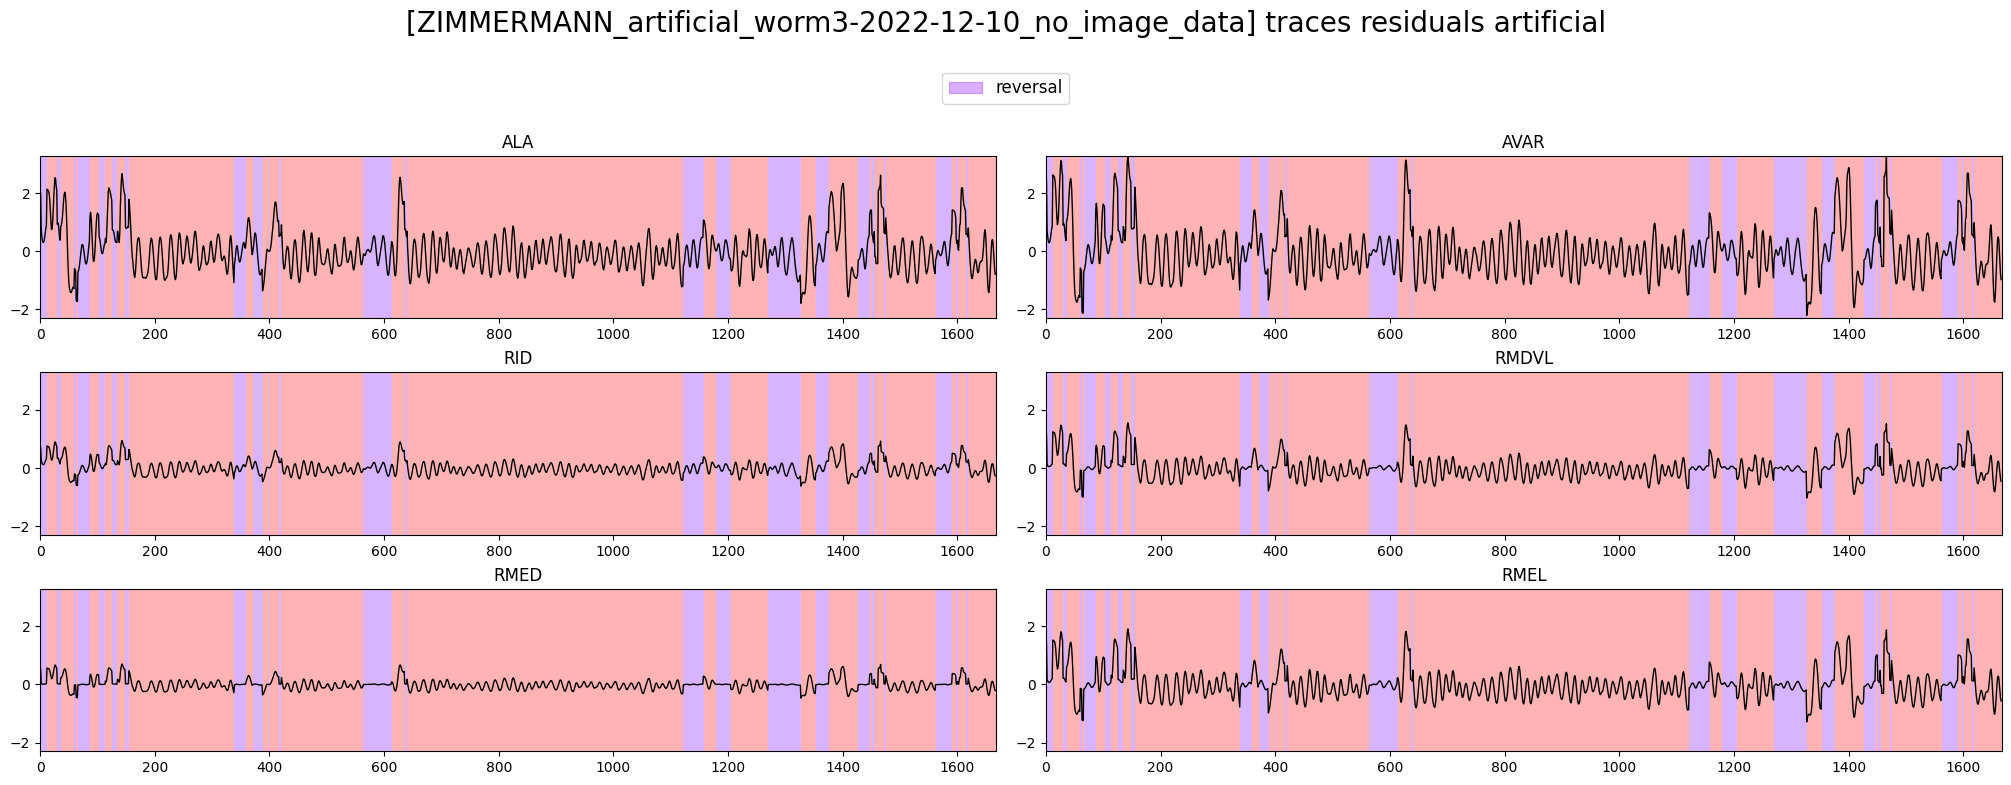

In [6]:
plot_utils.plot_traces(traces_residual_art[0], discrete_states_art[0]['REV'], f'[{filenames_art[0]}] traces residuals artificial', max_plots=6)

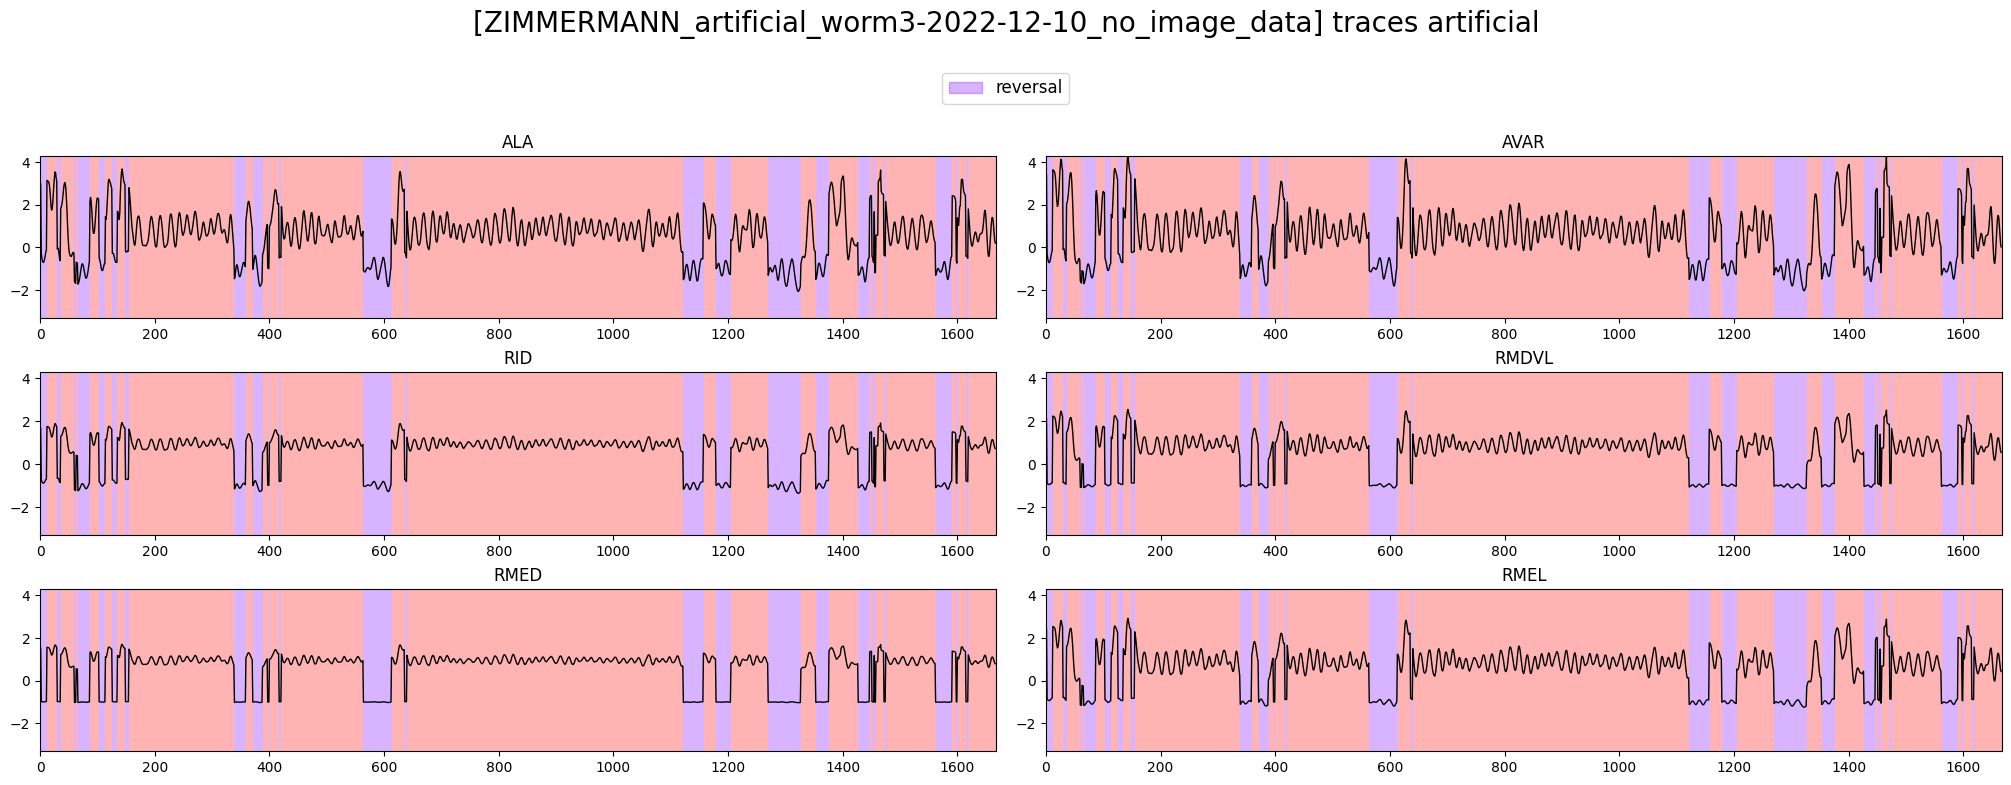

In [7]:
plot_utils.plot_traces(traces_art[0], discrete_states_art[0]['REV'], f'[{filenames_art[0]}] traces artificial', max_plots=6)

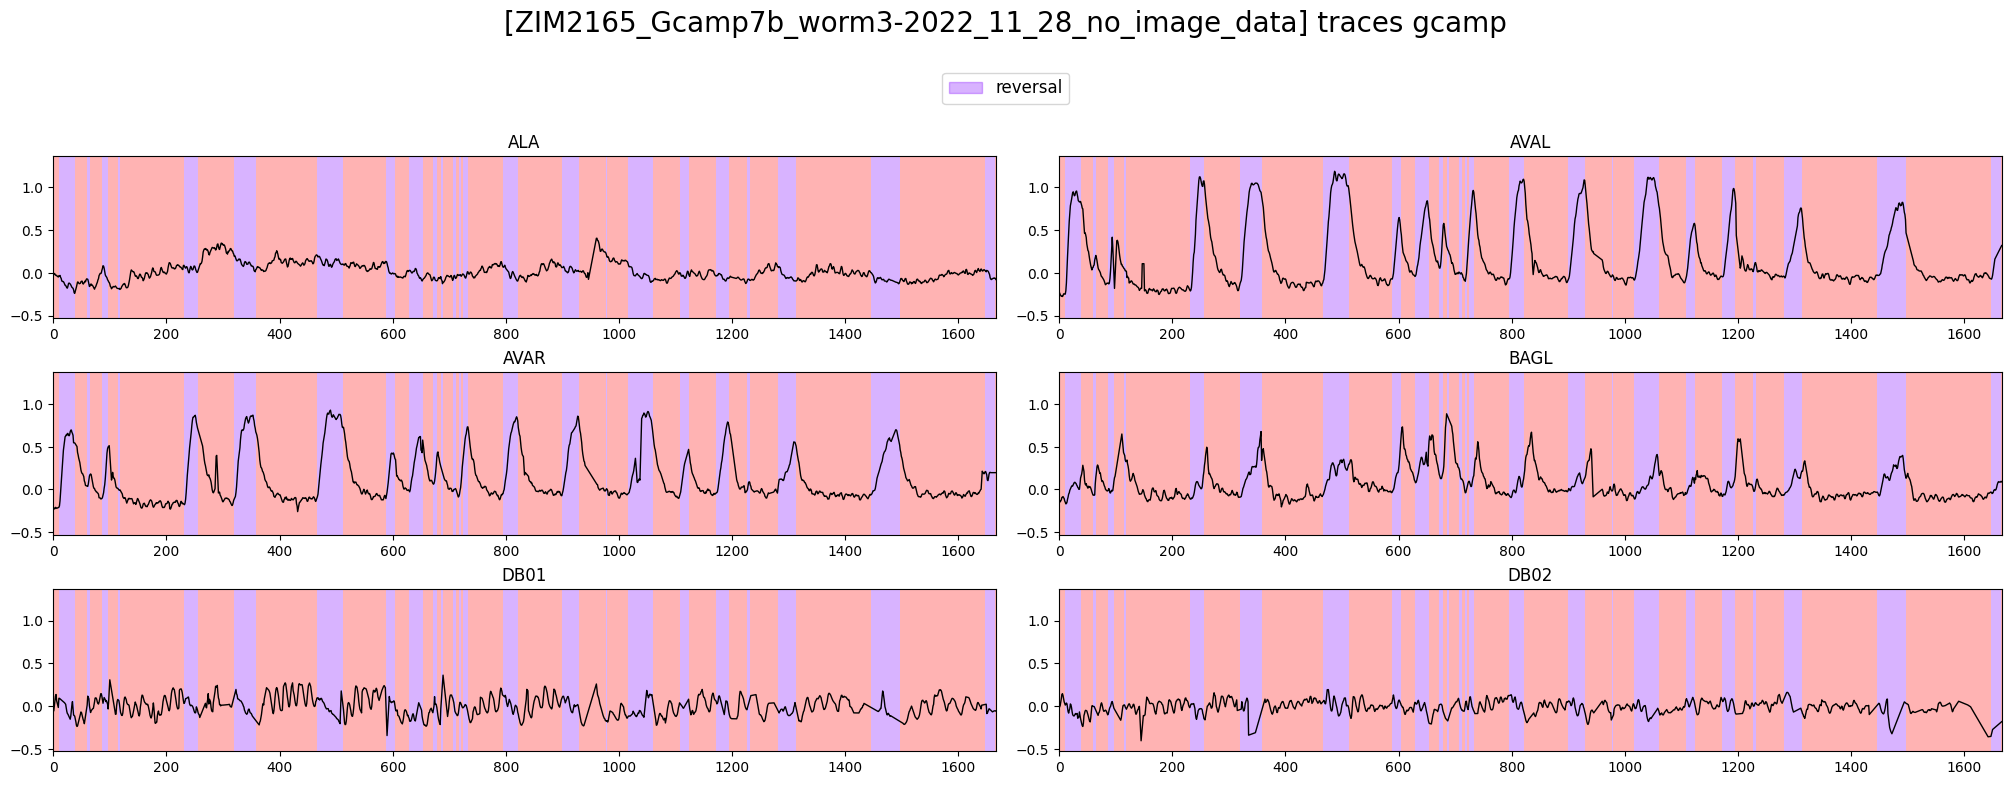

In [8]:
plot_utils.plot_traces(traces[0], discrete_states[0]['REV'], f'[{filenames[0]}] traces gcamp', max_plots=6)

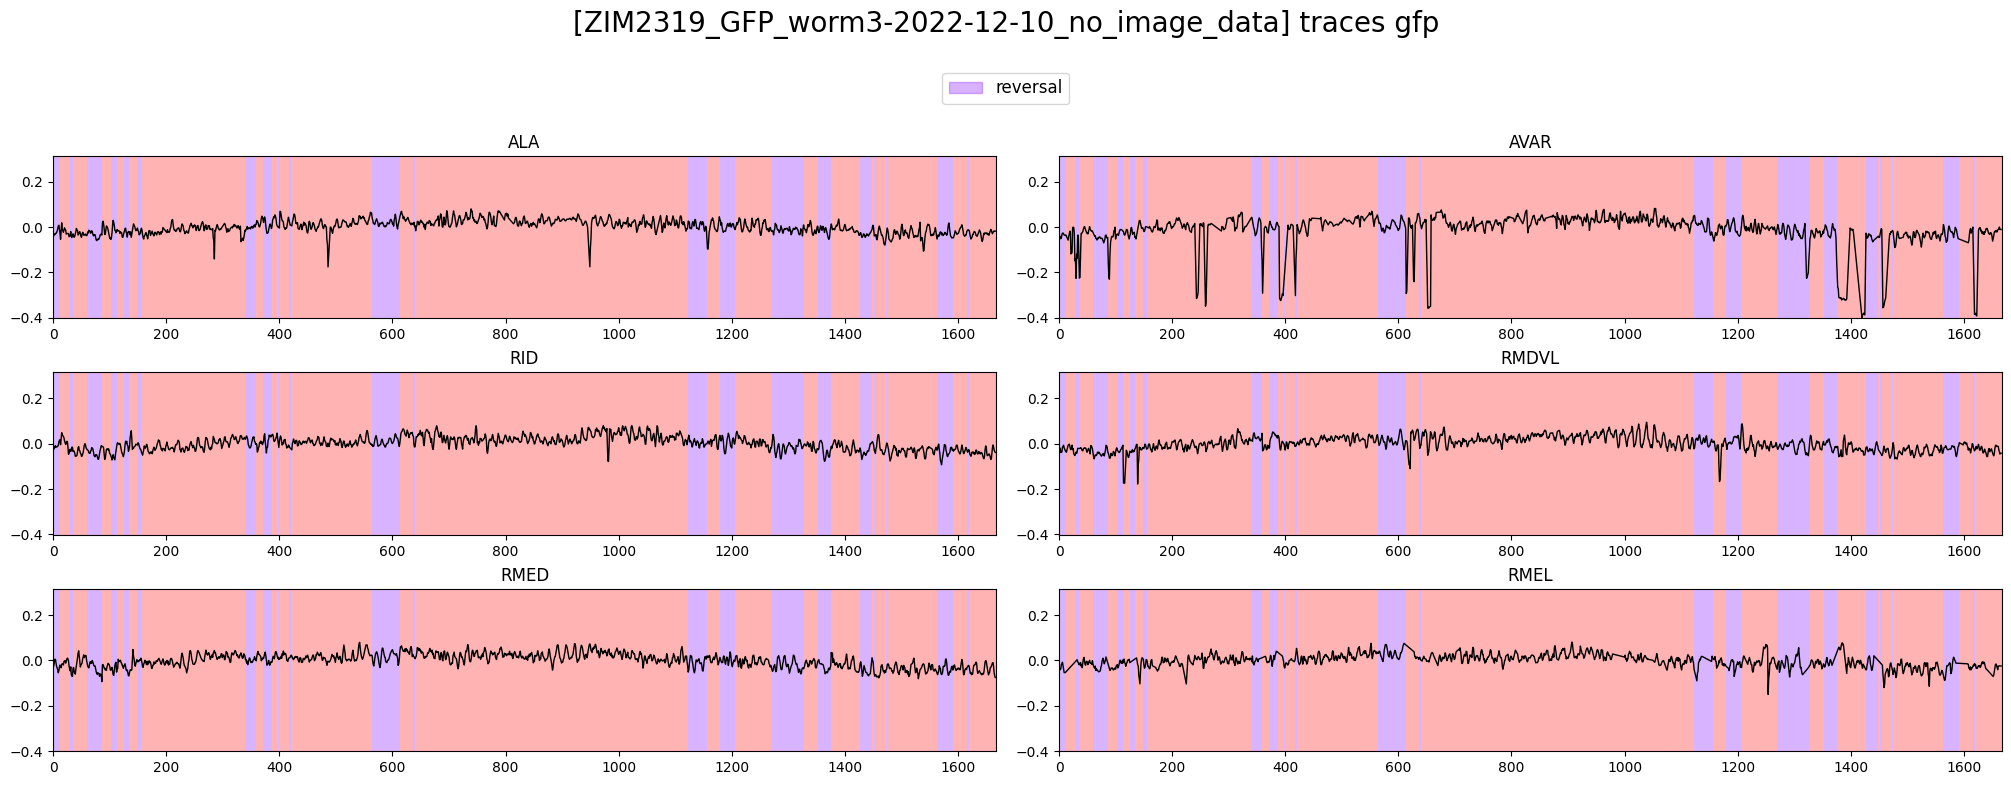

In [9]:
plot_utils.plot_traces(traces_gfp[0], discrete_states_gfp[0]['REV'], f'[{filenames_gfp[0]}] traces gfp', max_plots=6)

In [10]:
selection = ['REV', 'VENTRAL_TURN', 'DORSAL_TURN', 'PAUSE']

modes_manifold, traces_manifold, cca_loadings_man, vars_expl_man, vars_expl_man_rs = train_utils.get_manifolds([traces[0]],
																											   [discrete_states[0][selection]],
																				   n_cc=2, n_pc=5)

trace_residual = pd.DataFrame(data=traces[0].values - traces_manifold[0].values, columns=traces[0].columns)

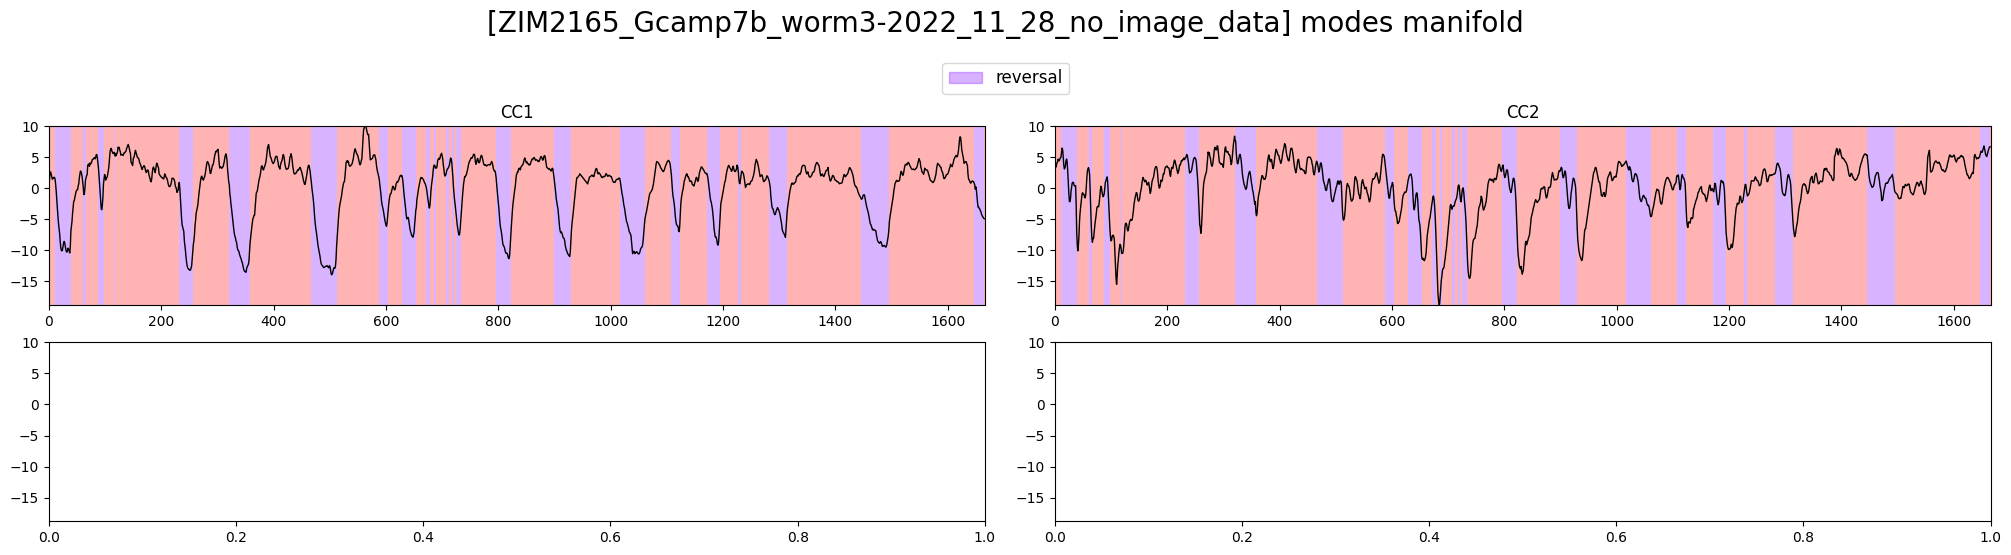

In [11]:
plot_utils.plot_traces(modes_manifold[0], discrete_states[0]['REV'], f'[{filenames[0]}] modes manifold', max_plots=4)

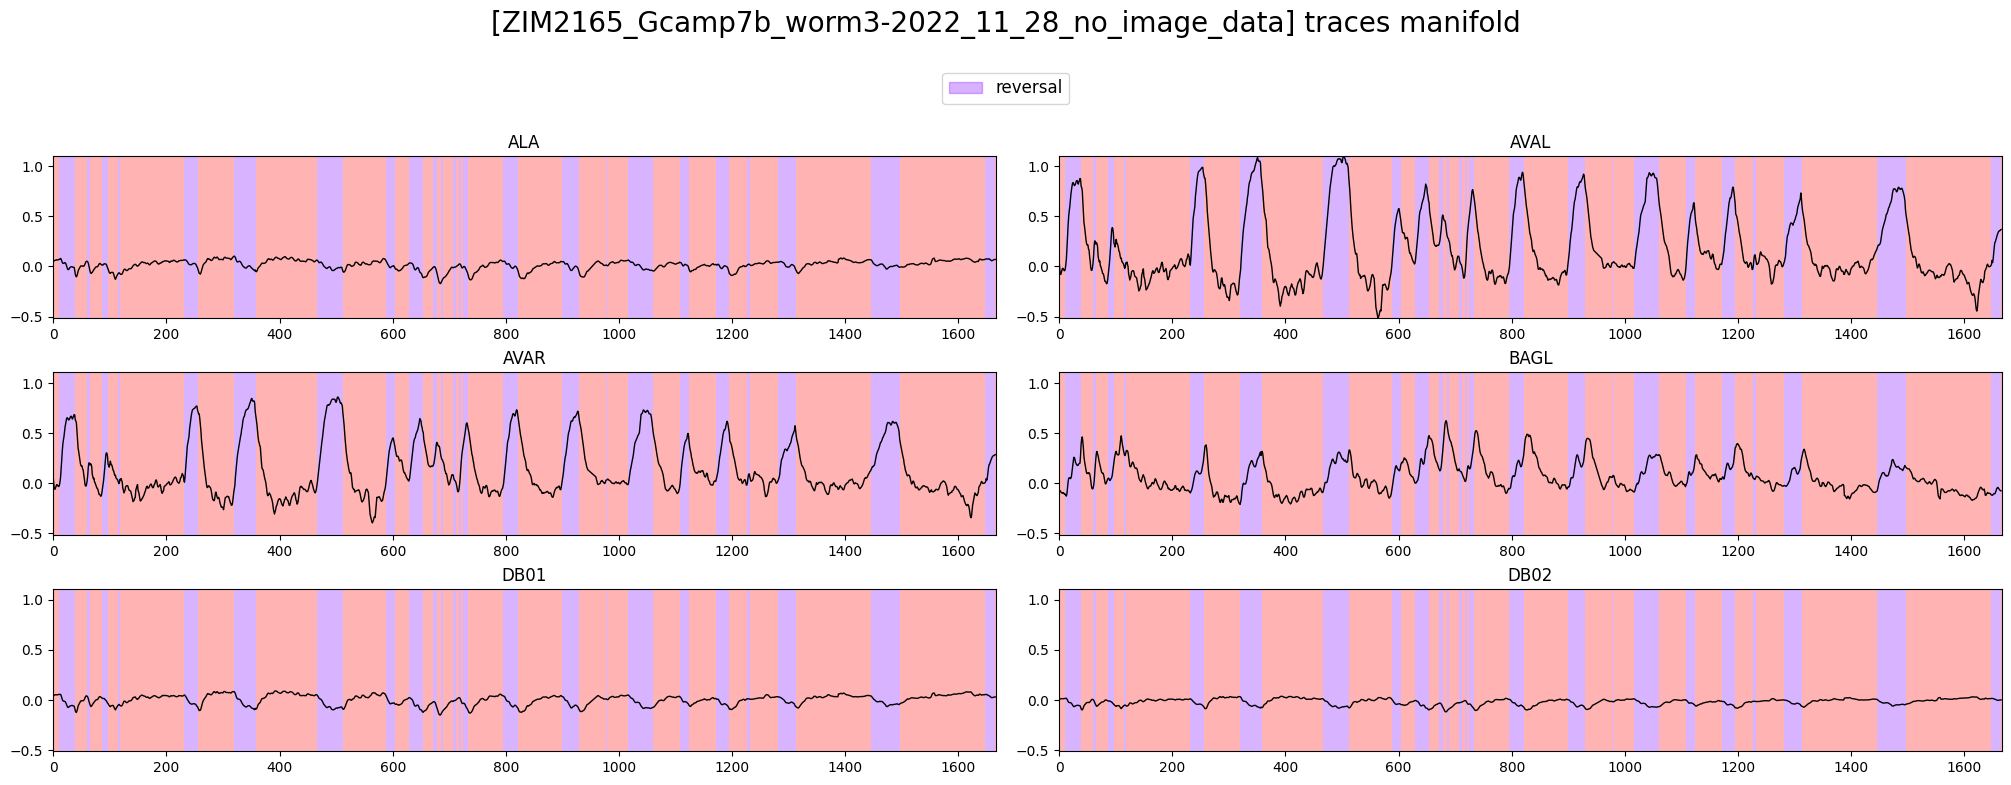

In [12]:
plot_utils.plot_traces(traces_manifold[0], discrete_states[0]['REV'], f'[{filenames[0]}] traces manifold', max_plots=6)

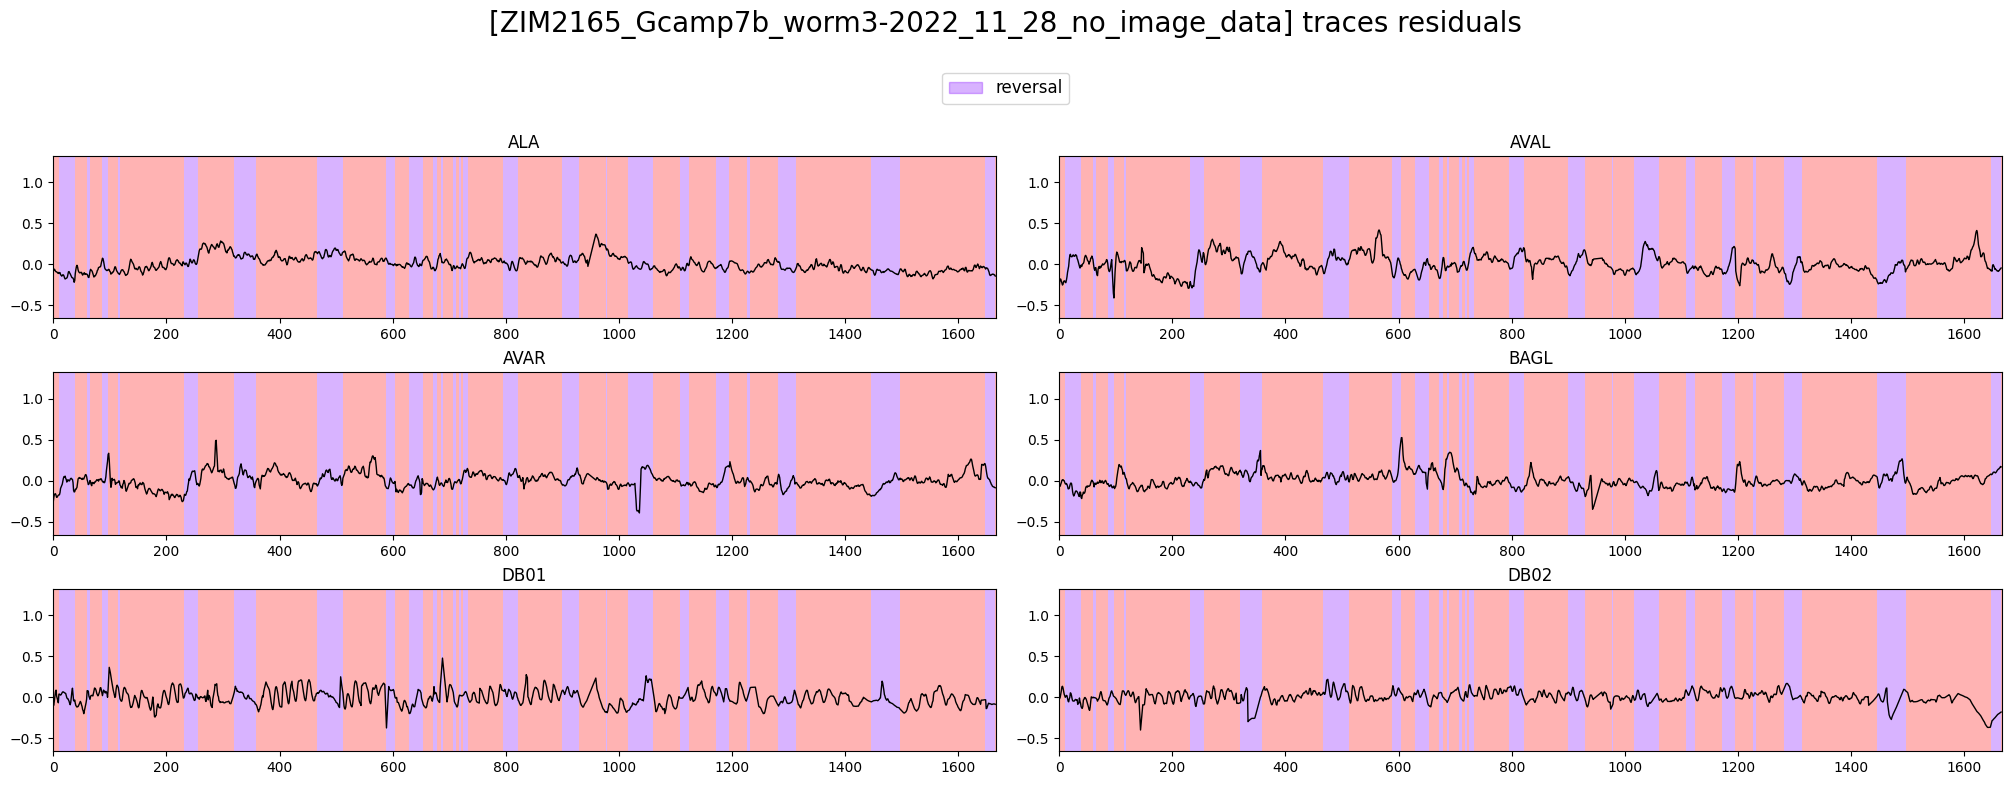

In [13]:
plot_utils.plot_traces(trace_residual, discrete_states[0]['REV'], f'[{filenames[0]}] traces residuals', max_plots=6)